Cellule 1 : Drive et photos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/scene/input
!unzip -q /content/drive/MyDrive/photos_objet.zip -d /content/scene/input
!ls /content/scene/input | wc -l

Mounted at /content/drive
1


Cellule 2 : dépôt Gaussian Splatting

In [ ]:
!git clone --recursive https://github.com/graphdeco-inria/gaussian-splatting.git /content/gaussian-splatting
!ls /content/gaussian-splatting/submodules

Cloning into '/content/gaussian-splatting'...
remote: Enumerating objects: 1053, done.
remote: Total 1053 (delta 0), reused 0 (delta 0), pack-reused 1053 (from 1)
Receiving objects: 100% (1053/1053), 78.72 MiB | 21.05 MiB/s, done.
Resolving deltas: 100% (593/593), done.
Submodule 'SIBR_viewers' (https://gitlab.inria.fr/sibr/sibr_core.git) registered for path 'SIBR_viewers'
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/graphdeco-inria/diff-gaussian-rasterization.git) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/fused-ssim' (https://github.com/rahul-goel/fused-ssim.git) registered for path 'submodules/fused-ssim'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/gaussian-splatting/SIBR_viewers'...
remote: Enumerating objects: 3293, done.        
remote: Counting objects: 100% (322/322), done.        
remote: Compressing objects:

Cellule 3 : installation

In [ ]:
import os
os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"
!pip install -q plyfile tqdm

# Correctif de compilation (en-tête manquant avec les compilateurs récents)
d = "/content/gaussian-splatting/submodules/diff-gaussian-rasterization/cuda_rasterizer"
for f in ["rasterizer_impl.h", "rasterizer_impl.cu"]:
    p = f"{d}/{f}"
    txt = open(p).read()
    if "#include <cstdint>" not in txt:
        open(p, "w").write("#include <cstdint>\n" + txt)

!pip install --no-build-isolation -v /content/gaussian-splatting/submodules/diff-gaussian-rasterization 2>&1 | tail -n 30
!pip install --no-build-isolation /content/gaussian-splatting/submodules/simple-knn 2>&1 | tail -n 5

  copying build/lib.linux-x86_64-cpython-313/diff_gaussian_rasterization/_C.cpython-313-x86_64-linux-gnu.so -> build/bdist.linux-x86_64/wheel/./diff_gaussian_rasterization
  copying build/lib.linux-x86_64-cpython-313/diff_gaussian_rasterization/__init__.py -> build/bdist.linux-x86_64/wheel/./diff_gaussian_rasterization
  running install_egg_info
  running egg_info
  creating diff_gaussian_rasterization.egg-info
  writing diff_gaussian_rasterization.egg-info/PKG-INFO
  writing dependency_links to diff_gaussian_rasterization.egg-info/dependency_links.txt
  writing top-level names to diff_gaussian_rasterization.egg-info/top_level.txt
  writing manifest file 'diff_gaussian_rasterization.egg-info/SOURCES.txt'
  reading manifest file 'diff_gaussian_rasterization.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file 'diff_gaussian_rasterization.egg-info/SOURCES.txt'
  Copying diff_gaussian_rasterization.egg-info to build/bdist.linux-x86_64/wheel/./diff_gaussian_rast

In [ ]:
import diff_gaussian_rasterization, simple_knn
print("OK")

OK


Cellule 4 : COLMAP (calcul des poses des caméras)

In [ ]:
import os
os.environ["QT_QPA_PLATFORM"] = "offscreen"
!apt-get -qq install -y colmap
!cd /content/gaussian-splatting && python convert.py -s /content/scene --no_gpu
!ls /content/scene/sparse/0

Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../00-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../01-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../02-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../03-libxtst6_2%3a1.2.3-1.1ubuntu0.1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1.2.3-1.1ubuntu0.1) ...
Selecting previously unselected package session-migration.
Preparing to unpack .../04-session-migration_0.3.9build1_amd64.deb ...
Unpacking session-migration (0.3.

In [ ]:
from PIL import Image, ImageOps
import glob, collections
files = sorted(glob.glob("/content/scene/input/**/*.*", recursive=True))
sizes = collections.Counter(ImageOps.exif_transpose(Image.open(f)).size for f in files)
print(sizes)

Counter({(960, 1280): 31, (1280, 960): 19})


In [ ]:
!sed -i 's/--ImageReader.single_camera 1/--ImageReader.single_camera 0/' /content/gaussian-splatting/convert.py
!grep -n "single_camera" /content/gaussian-splatting/convert.py

38:        --ImageReader.single_camera 0 \


In [ ]:
import os
os.environ["QT_QPA_PLATFORM"] = "offscreen"
!cd /content/scene && rm -rf distorted sparse images stereo run-colmap-*.sh
!cd /content/gaussian-splatting && python convert.py -s /content/scene --no_gpu 2>&1 | tail -n 25

I20261119 11:09:50.903651 16319 undistortion.cc:210] Undistorting image [27/46]
I20261119 11:09:51.089851 16319 undistortion.cc:210] Undistorting image [28/46]
I20261119 11:09:51.317173 16319 undistortion.cc:210] Undistorting image [29/46]
I20261119 11:09:51.498281 16319 undistortion.cc:210] Undistorting image [30/46]
I20261119 11:09:51.735360 16319 undistortion.cc:210] Undistorting image [31/46]
I20261119 11:09:51.925412 16319 undistortion.cc:210] Undistorting image [32/46]
I20261119 11:09:52.101531 16319 undistortion.cc:210] Undistorting image [33/46]
I20261119 11:09:52.333249 16319 undistortion.cc:210] Undistorting image [34/46]
I20261119 11:09:52.499135 16319 undistortion.cc:210] Undistorting image [35/46]
I20261119 11:09:52.748485 16319 undistortion.cc:210] Undistorting image [36/46]
I20261119 11:09:52.916522 16319 undistortion.cc:210] Undistorting image [37/46]
I20261119 11:09:53.150676 16319 undistortion.cc:210] Undistorting image [38/46]
I20261119 11:09:53.326763 16319 undistor

In [ ]:
!find /content/scene/images -mindepth 2 -type f -exec mv {} /content/scene/images/ \;
!find /content/scene/images -mindepth 1 -type d -empty -delete
!ls /content/scene/images | wc -l
!ls /content/scene/sparse/0

46
cameras.bin  images.bin  points3D.bin


In [ ]:
!cp -r /content/scene /content/drive/MyDrive/scene_gs

## Reprise de session (nouvelle session Colab)
La scène COLMAP et les modèles sont sauvegardés sur Drive. Dans une nouvelle session :
exécuter cette section (sans refaire COLMAP), puis l'entraînement (ignoré si le modèle existe déjà).

Cellule 2 : restaurer depuis Drive

In [12]:
from google.colab import drive
drive.mount('/content/drive')
import os
if not os.path.exists("/content/scene"):
    !cp -r /content/drive/MyDrive/scene_gs /content/scene
if os.path.exists("/content/drive/MyDrive/nounours_gs") and not os.path.exists("/content/output/nounours"):
    !mkdir -p /content/output
    !cp -r /content/drive/MyDrive/nounours_gs /content/output/nounours
!ls /content/scene/images | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
46


Cellule 3 : installation (clone + compilation)

In [13]:
import os
if not os.path.exists("/content/gaussian-splatting"):
    !git clone --recursive https://github.com/graphdeco-inria/gaussian-splatting.git /content/gaussian-splatting
os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"
!pip install -q plyfile tqdm lpips
d = "/content/gaussian-splatting/submodules/diff-gaussian-rasterization/cuda_rasterizer"
for f in ["rasterizer_impl.h", "rasterizer_impl.cu"]:
    p = f"{d}/{f}"
    txt = open(p).read()
    if "#include <cstdint>" not in txt:
        open(p, "w").write("#include <cstdint>\n" + txt)
!pip install --no-build-isolation /content/gaussian-splatting/submodules/diff-gaussian-rasterization 2>&1 | tail -n 3
!pip install --no-build-isolation /content/gaussian-splatting/submodules/simple-knn 2>&1 | tail -n 3
import diff_gaussian_rasterization, simple_knn
print("OK")

Cloning into '/content/gaussian-splatting'...
remote: Enumerating objects: 1053, done.
remote: Total 1053 (delta 0), reused 0 (delta 0), pack-reused 1053 (from 1)
Receiving objects: 100% (1053/1053), 78.72 MiB | 30.70 MiB/s, done.
Resolving deltas: 100% (593/593), done.
Submodule 'SIBR_viewers' (https://gitlab.inria.fr/sibr/sibr_core.git) registered for path 'SIBR_viewers'
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/graphdeco-inria/diff-gaussian-rasterization.git) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/fused-ssim' (https://github.com/rahul-goel/fused-ssim.git) registered for path 'submodules/fused-ssim'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/gaussian-splatting/SIBR_viewers'...
remote: Enumerating objects: 3293, done.        
remote: Counting objects: 100% (322/322), done.        
remote: Compressing objects:

Cellule 3 : recréer le sous-dossier des images

In [20]:
!mkdir -p /content/scene/images/photos_objet
!find /content/scene/images -maxdepth 1 -type f -exec cp {} /content/scene/images/photos_objet/ \;
!ls /content/scene/images/photos_objet | wc -l
!ls "/content/scene/images/photos_objet/WhatsApp Image 2026-11-18 at 16.49.06.jpeg"

46
'/content/scene/images/photos_objet/WhatsApp Image 2026-11-18 at 16.49.06.jpeg'


Cellule 4 : rendu des vues de test

In [21]:
!cd /content/gaussian-splatting && python render.py -m /content/output/nounours --iteration 7000 --skip_train
!cd /content/gaussian-splatting && python render.py -m /content/output/nounours --iteration 30000 --skip_train

Looking for config file in /content/output/nounours/cfg_args
Config file found: /content/output/nounours/cfg_args
Rendering /content/output/nounours
Loading trained model at iteration 7000 [25/11 12:35:48]
------------LLFF HOLD------------- [25/11 12:35:48]
Reading camera 46/46 [25/11 12:35:48]
Loading Training Cameras [25/11 12:35:48]
Loading Test Cameras [25/11 12:35:50]
Rendering progress: 100% 6/6 [00:05<00:00,  1.18it/s]
Looking for config file in /content/output/nounours/cfg_args
Config file found: /content/output/nounours/cfg_args
Rendering /content/output/nounours
Loading trained model at iteration 30000 [25/11 12:36:01]
------------LLFF HOLD------------- [25/11 12:36:01]
Reading camera 46/46 [25/11 12:36:01]
Loading Training Cameras [25/11 12:36:01]
Loading Test Cameras [25/11 12:36:03]
Rendering progress: 100% 6/6 [00:05<00:00,  1.17it/s]


Cellule 5 : métriques

In [22]:
!cd /content/gaussian-splatting && python metrics.py -m /content/output/nounours


Scene: /content/output/nounours
Method: ours_7000
Metric evaluation progress:   0% 0/6 [00:00<?, ?it/s]Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth

  0% 0.00/528M [00:00<?, ?B/s]
  3% 13.2M/528M [00:00<00:03, 139MB/s]
  6% 30.2M/528M [00:00<00:03, 161MB/s]
  9% 47.4M/528M [00:00<00:02, 169MB/s]
 12% 64.5M/528M [00:00<00:02, 173MB/s]
 15% 81.8M/528M [00:00<00:02, 176MB/s]
 19% 98.5M/528M [00:00<00:02, 173MB/s]
 22% 115M/528M [00:00<00:02, 165MB/s] 
 25% 132M/528M [00:00<00:02, 168MB/s]
 28% 148M/528M [00:00<00:02, 167MB/s]
 31% 164M/528M [00:01<00:02, 164MB/s]
 34% 180M/528M [00:01<00:02, 162MB/s]
 37% 195M/528M [00:01<00:02, 159MB/s]
 40% 211M/528M [00:01<00:02, 160MB/s]
 43% 229M/528M [00:01<00:01, 167MB/s]
 47% 248M/528M [00:01<00:01, 177MB/s]
 50% 266M/528M [00:01<00:01, 182MB/s]
 54% 284M/528M [00:01<00:01, 156MB/s]
 57% 299M/528M [00:01<00:01, 148MB/s]
 59% 314M/528M [00:02<00:01, 142MB/s]
 62% 328

Cellule 6 : tableau CSV

In [23]:
import json, os, pandas as pd
r = json.load(open("/content/output/nounours/results.json"))
rows = []
for k, v in r.items():
    it = k.split("_")[1]
    ply = f"/content/output/nounours/point_cloud/iteration_{it}/point_cloud.ply"
    rows.append({"iterations": int(it), "PSNR": v["PSNR"], "SSIM": v["SSIM"],
                 "LPIPS": v["LPIPS"], "taille_Mo": round(os.path.getsize(ply) / 1024**2, 2)})
df = pd.DataFrame(rows).sort_values("iterations")
os.makedirs("/content/results/tables", exist_ok=True)
df.to_csv("/content/results/tables/04_gs_metrics.csv", index=False)
print(df)

   iterations       PSNR      SSIM     LPIPS  taille_Mo
0        7000  12.321170  0.684017  0.478482     117.74
1       30000  11.587837  0.642455  0.503815     219.46


Cellule 7 : figure photos réelles et rendus

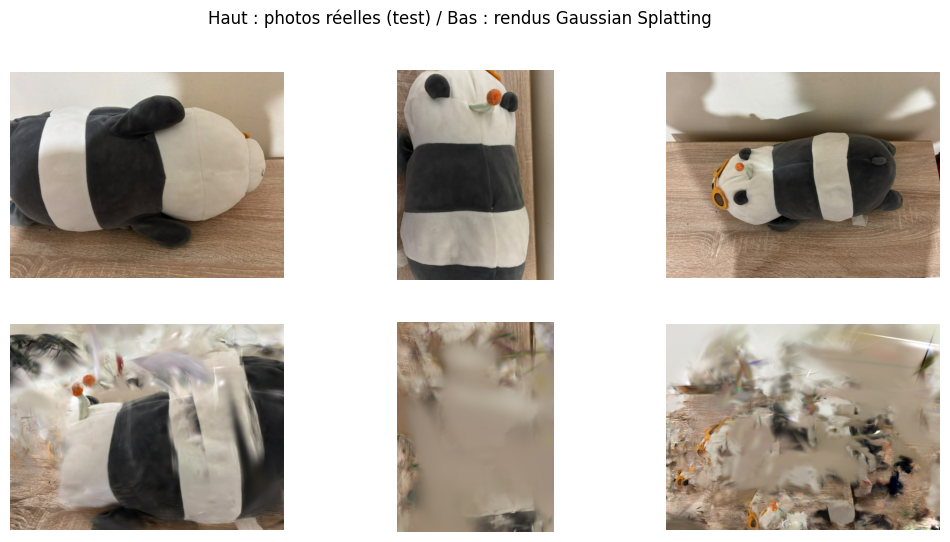

In [24]:
import matplotlib.pyplot as plt, glob
from PIL import Image
base = "/content/output/nounours/test/ours_30000"
R = sorted(glob.glob(f"{base}/renders/*.png"))[:3]
G = sorted(glob.glob(f"{base}/gt/*.png"))[:3]
fig, ax = plt.subplots(2, len(R), figsize=(4 * len(R), 6))
for i in range(len(R)):
    ax[0, i].imshow(Image.open(G[i])); ax[0, i].axis("off")
    ax[1, i].imshow(Image.open(R[i])); ax[1, i].axis("off")
fig.suptitle("Haut : photos réelles (test) / Bas : rendus Gaussian Splatting")
os.makedirs("/content/results/figures", exist_ok=True)
fig.savefig("/content/results/figures/04_gs_renders.png", dpi=150, bbox_inches="tight")
plt.show()

Cellule 8 : sauvegarder avant de fermer

In [25]:
!cp -r /content/results /content/drive/MyDrive/results_04
!cd /content && zip -r results_04.zip results
from google.colab import files
files.download("/content/results_04.zip")

  adding: results/ (stored 0%)
  adding: results/tables/ (stored 0%)
  adding: results/tables/04_gs_metrics.csv (deflated 24%)
  adding: results/figures/ (stored 0%)
  adding: results/figures/04_gs_renders.png (deflated 0%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cellule 4 : entraînement (ignoré si le modèle existe)

In [ ]:
import os, time
model_ply = "/content/output/nounours/point_cloud/iteration_30000/point_cloud.ply"
if os.path.exists(model_ply):
    print("Modèle déjà présent : entraînement ignoré")
else:
    t0 = time.time()
    !cd /content/gaussian-splatting && python train.py -s /content/scene -m /content/output/nounours --eval --iterations 30000 --test_iterations 7000 30000 --save_iterations 7000 30000
    print("Temps d'entraînement (s) :", round(time.time() - t0))
    !cp -r /content/output/nounours /content/drive/MyDrive/nounours_gs